Simulation took 33.450706005096436 seconds
{'grid_building_time': 6.74e-06, 'num_collisions': 1982169, 'num_crossings': 2344048, 'total_time': 33.334108817, 'trace_time': 33.334102077}


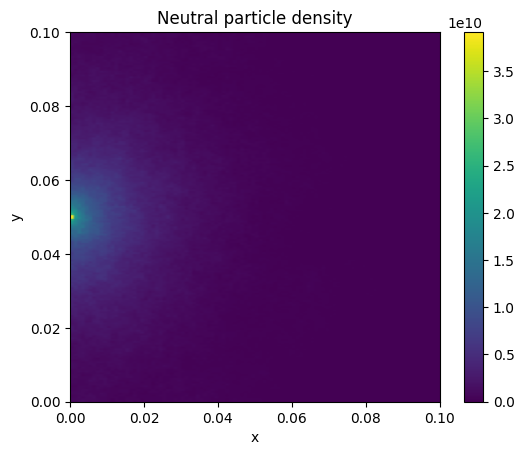

In [2]:
import numpy as np
from matplotlib import pyplot as plt
import math
import json
import subprocess
import time

config = {}

Lx = 0.1
Ly = 0.1
Lz = 0.1
nx = 100
ny = 200
nz = 1

config["mesh"] = {
    "type": "voxel",
    "Lx": Lx,
    "Ly": Ly,
    "Lz": Lz,
    "nx": nx,
    "ny": ny,
    "nz": nz
}

ncells = nx * ny * nz

plasma_dens = np.zeros(ncells, dtype=np.float64)
plasma_temp = np.zeros(ncells, dtype=np.float64)
plasma_vel_x = np.zeros(ncells, dtype=np.float64)
plasma_vel_y = np.zeros(ncells, dtype=np.float64)
plasma_vel_z = np.zeros(ncells, dtype=np.float64)


for i in range(ncells):
    plasma_dens[i] = 1.0e21

for i in range(ncells):
    plasma_temp[i] = 1.0

for i in range(ncells):
    plasma_vel_x[i] = 0.1

for i in range(ncells):
    plasma_vel_y[i] = 0

config["background"] = {
    "plasma_dens": plasma_dens.tolist(),
    "plasma_temp": plasma_temp.tolist(),
    "plasma_vel_x": plasma_vel_x.tolist(),
    "plasma_vel_y": plasma_vel_y.tolist(),
    "plasma_vel_z": plasma_vel_z.tolist()
}

config["sources"] = [
    {
        "type": "point",
        "pos": [0, 0.05, 0.05],
        "vel_mean": [100, 0, 0],
        "vel_stddev": 100,
        "n_particles": 1000,
        "intensity": 1.0e10,
        "angle_min": -math.pi/2,
        "angle_max": math.pi/2,
    }
]

config["boundary_conditions"] = [
    "reflective",
    "reflective",
    "reflective",
    "absorbing",
    "reflective",
    "reflective"
]

config["max_steps"] = 1000000
config["seed"] = 0

config["t_final"] = 1.0e-4

inputstring = json.dumps(config)

with open("input.json", "w") as f:
    f.write(inputstring)

start_time = time.time()
subprocess.check_output(["neptune-json"]).decode("utf-8")
end_time = time.time()

print("Simulation took", end_time - start_time, "seconds")

with open("output.json", "r") as f:
    outputstring = f.read()

output = json.loads(outputstring)

stats = output["stats"]
print(stats)

neutral_density = np.array(output["density"])

neutral_density_reshaped = np.reshape(neutral_density, (nx, ny), order='F')

c = plt.imshow(np.transpose(neutral_density_reshaped), extent=[0, Lx, 0, Ly])
plt.title("Neutral particle density")
plt.colorbar(c)
plt.xlabel("x")
plt.ylabel("y")
plt.show()
